# Exploratory Data Analysis (EDA) on Superstore Retail Sales
Perform data wrangling, missing-value profiling, and uncover commercial sales
distributions.

**DETAILED PROBLEM STATEMENT & REQUIREMENTS**

Analyze customer purchase volume, monthly seasonality, category-wise revenue, and discount
sensitivity using Python (Pandas/Seaborn) or Excel. Formulate at least 5 executive takeaways.

SUGGESTED TECHNICAL APPROACH

1. Download the Superstore Sales dataset.
2. Handle null values, parse order dates, and extract
Year-Month.
3. Group by Product Category, Region, and Customer Segment to compute
aggregate Sales & Profit.
4. Plot monthly sales velocity and discount-vs-profit scatter plots.
5. Document business observations in Markdown.

# Setup, Upload (Opsional) & Parsing Struktur CSV

In [1]:
import os
import csv
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

# Uncomment 2 baris di bawah jika ingin upload CSV lewat pop-up Colab:
# from google.colab import files
# uploaded = files.upload()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PALETTE = {
    "primary": "#1f4e79",
    "secondary": "#2e8b57",
    "accent": "#d95f02",
    "danger": "#c0392b",
    "muted": "#7f8c8d",
    "Tech": "#1f77b4",
    "Office": "#2ca02c",
    "Furniture": "#d95f02",
}

DATA_PATH = "data/superstore_sales.csv" if os.path.exists("data/superstore_sales.csv") else "superstore_sales.csv"

def load_superstore_tables(filepath: str):
    """Memisahkan tabel Orders, People, dan Returns dari superstore_sales.csv."""
    orders_rows, people_rows, returns_rows = [], [], []
    section = "orders"

    with open(filepath, "r", encoding="latin1", newline="") as f:
        reader = csv.reader(f)
        orders_header = next(reader)
        for row in reader:
            if row == ["Person", "Region"]:
                section = "people"
                continue
            if row == ["Returned", "Order ID"]:
                section = "returns"
                continue
            if section == "orders":
                orders_rows.append(row)
            elif section == "people":
                people_rows.append(row)
            elif section == "returns":
                returns_rows.append(row)

    orders_df = pd.DataFrame(orders_rows, columns=orders_header)
    people_df = pd.DataFrame(people_rows, columns=["Regional_Manager", "Region"])
    returns_df = pd.DataFrame(returns_rows, columns=["Returned", "Order ID"])
    return orders_df, people_df, returns_df

orders_raw, people_df, returns_raw = load_superstore_tables(DATA_PATH)
print(f"Orders raw shape : {orders_raw.shape}")
print(f"People shape     : {people_df.shape}")
print(f"Returns raw shape: {returns_raw.shape}")
display(people_df)
orders_raw.head(3)

Orders raw shape : (9994, 21)
People shape     : (4, 2)
Returns raw shape: (800, 2)


,Regional_Manager,Region
0,Anna Andreadi,West
1,Chuck Magee,East
2,Kelly Williams,Central
3,Cassandra Brandow,South


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0,219.582
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0,6.8714


# Data Wrangling, Missing-Value Profiling & Feature Engineering

In [2]:
df = orders_raw.replace("", np.nan).copy()

# 1. Missing-value profiling
missing_profile = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Pct": (df.isna().mean() * 100).round(3)
})
print("--- Missing-Value Profile (Orders Table) ---")
display(missing_profile[missing_profile["Missing_Count"] > 0])

print("\nRows with missing Postal Code:")
display(df[df["Postal Code"].isna()][["Order ID", "Order Date", "Customer Name", "City", "State", "Region"]].head(11))

# 2. Type casting & date parsing
df["Row ID"] = df["Row ID"].astype(int)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df["Sales"] = df["Sales"].astype(float)
df["Quantity"] = df["Quantity"].astype(int)
df["Discount"] = df["Discount"].astype(float)
df["Profit"] = df["Profit"].astype(float)

# 3. Duplicate check (excluding Row ID)
feature_cols = [c for c in df.columns if c != "Row ID"]
dup_mask = df.duplicated(subset=feature_cols, keep="first")
print(f"\nExact duplicate order line items found (excl. Row ID): {dup_mask.sum()}")
if dup_mask.sum() > 0:
    display(df[df.duplicated(subset=feature_cols, keep=False)][["Row ID", "Order ID", "Order Date", "Product ID", "Sales", "Quantity", "Discount", "Profit"]])
df = df.loc[~dup_mask].copy()

# 4. Postal Code standardization & imputation (Burlington, VT -> 05401)
short_zips = df["Postal Code"].dropna().str.len().lt(5).sum()
print(f"ZIP codes missing leading zero (4-digit): {short_zips}")
df["Postal Code"] = df["Postal Code"].fillna("05401").astype(str).str.strip().str.zfill(5)

# 5. Deduplicate Returns & merge People + Returns
returns_clean = returns_raw.drop_duplicates(subset=["Order ID"]).copy()
returns_clean["Is_Returned"] = returns_clean["Returned"] == "Yes"
print(f"Returns deduplicated: {len(returns_raw)} rows -> {len(returns_clean)} unique returned Order IDs")

df = df.merge(people_df, on="Region", how="left")
df = df.merge(returns_clean[["Order ID", "Is_Returned"]], on="Order ID", how="left")
df["Is_Returned"] = df["Is_Returned"].fillna(False)

# 6. Feature engineering
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month_Name"] = df["Order Date"].dt.strftime("%b")
df["Year_Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Quarter"] = df["Order Date"].dt.to_period("Q").astype(str)
df["Shipping_Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit_Margin"] = df["Profit"] / df["Sales"]
df["Discount_Tier"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0.0, 0.20, 0.40, 1.0],
    labels=["No Discount (0%)", "Low (1%–20%)", "Medium (21%–40%)", "High (>40%)"]
)

# 7. Validation checks
assert df.isna().sum().sum() == 0, "Unexpected nulls remain!"
assert (df["Shipping_Days"] >= 0).all(), "Found Ship Date earlier than Order Date!"
assert (df["Sales"] > 0).all() and (df["Quantity"] > 0).all(), "Invalid Sales or Quantity!"

# Clean dataset KPI summary
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
overall_margin = total_profit / total_sales * 100
unique_orders = df["Order ID"].nunique()
unique_customers = df["Customer ID"].nunique()
returned_orders = df.loc[df["Is_Returned"], "Order ID"].nunique()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Clean Line Items", "Unique Orders", "Unique Customers",
        "Date Range", "Total Sales", "Total Profit",
        "Overall Profit Margin", "Total Units Sold", "Order Return Rate"
    ],
    "Value": [
        f"{len(df):,}", f"{unique_orders:,}", f"{unique_customers:,}",
        f"{df['Order Date'].min().date()} to {df['Order Date'].max().date()}",
        f"${total_sales:,.2f}", f"${total_profit:,.2f}",
        f"{overall_margin:.2f}%", f"{df['Quantity'].sum():,}",
        f"{returned_orders / unique_orders * 100:.2f}% ({returned_orders:,} orders)"
    ]
})
print("\n--- Clean Dataset Health & KPI Summary ---")
display(kpi_summary)

--- Missing-Value Profile (Orders Table) ---


,Missing_Count,Missing_Pct
Postal Code,11,0.11



Rows with missing Postal Code:


,Order ID,Order Date,Customer Name,City,State,Region
2234,CA-2018-104066,12/5/2018,Quincy Jones,Burlington,Vermont,East
5274,CA-2016-162887,11/7/2016,Stewart Visinsky,Burlington,Vermont,East
8798,US-2017-150140,4/6/2017,Valerie Mitchum,Burlington,Vermont,East
9146,US-2017-165505,1/23/2017,Claudia Bergmann,Burlington,Vermont,East
9147,US-2017-165505,1/23/2017,Claudia Bergmann,Burlington,Vermont,East
9148,US-2017-165505,1/23/2017,Claudia Bergmann,Burlington,Vermont,East
9386,US-2018-127292,1/19/2018,Raymond Messe,Burlington,Vermont,East
9387,US-2018-127292,1/19/2018,Raymond Messe,Burlington,Vermont,East
9388,US-2018-127292,1/19/2018,Raymond Messe,Burlington,Vermont,East
9389,US-2018-127292,1/19/2018,Raymond Messe,Burlington,Vermont,East



Exact duplicate order line items found (excl. Row ID): 1


,Row ID,Order ID,Order Date,Product ID,Sales,Quantity,Discount,Profit
3405,3406,US-2015-150119,2015-04-23,FUR-CH-10002965,281.372,2,0.3,-12.0588
3406,3407,US-2015-150119,2015-04-23,FUR-CH-10002965,281.372,2,0.3,-12.0588


ZIP codes missing leading zero (4-digit): 438
Returns deduplicated: 800 rows -> 296 unique returned Order IDs



--- Clean Dataset Health & KPI Summary ---


,Metric,Value
0,Clean Line Items,"9,993"
1,Unique Orders,"5,009"
2,Unique Customers,793
3,Date Range,2015-01-03 to 2018-12-30
4,Total Sales,"$2,296,919.49"
5,Total Profit,"$286,409.08"
6,Overall Profit Margin,12.47%
7,Total Units Sold,"37,871"
8,Order Return Rate,5.91% (296 orders)


# Customer Purchase Volume & Segment Economics

In [3]:
customer_df = (
    df.groupby(["Customer ID", "Customer Name", "Segment"], as_index=False)
      .agg(
          Orders=("Order ID", "nunique"),
          Line_Items=("Row ID", "count"),
          Total_Quantity=("Quantity", "sum"),
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Avg_Discount=("Discount", "mean")
      )
)
customer_df["AOV"] = customer_df["Total_Sales"] / customer_df["Orders"]
customer_df["Profit_Margin_Pct"] = customer_df["Total_Profit"] / customer_df["Total_Sales"] * 100

# 1. Tampilkan deskripsi statistik ringkas profil pelanggan
print("--- Analisis Statistik Profil Pelanggan ---")
repeat_pct = (customer_df["Orders"] >= 2).mean() * 100
print(f"Pelanggan Berulang (>= 2 order): {(customer_df['Orders'] >= 2).sum()} / {len(customer_df)} ({repeat_pct:.2f}%)")
display(customer_df[["Orders", "Line_Items", "Total_Quantity", "Total_Sales", "Total_Profit", "AOV"]].describe().round(2))

--- Analisis Statistik Profil Pelanggan ---
Pelanggan Berulang (>= 2 order): 781 / 793 (98.49%)


,Orders,Line_Items,Total_Quantity,Total_Sales,Total_Profit,AOV
count,793.00,793.00,793.00,793.00,793.00,793.00
mean,6.32,12.60,47.76,2896.49,361.17,460.10
std,2.55,6.24,24.84,2628.41,894.25,433.39
min,1.00,1.00,2.00,4.83,-6626.39,2.42
25%,5.00,8.00,30.00,1146.05,36.61,213.26
50%,6.00,12.00,44.00,2256.39,227.83,362.50
75%,8.00,16.00,63.00,3785.28,560.01,550.38
max,17.00,37.00,150.00,25043.05,8981.32,5008.61


In [4]:
seg_summary = (
    df.groupby("Segment", as_index=False)
      .agg(
          Customers=("Customer ID", "nunique"),
          Orders=("Order ID", "nunique"),
          Line_Items=("Row ID", "count"),
          Quantity=("Quantity", "sum"),
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Avg_Discount=("Discount", "mean")
      )
      .sort_values("Sales", ascending=False)
)
seg_summary["Sales_Share_Pct"] = seg_summary["Sales"] / seg_summary["Sales"].sum() * 100
seg_summary["Profit_Margin_Pct"] = seg_summary["Profit"] / seg_summary["Sales"] * 100
seg_summary["AOV"] = seg_summary["Sales"] / seg_summary["Orders"]

print("--- Ringkasan Kinerja Berdasarkan Segmen Pelanggan ---")
display(seg_summary.round(2))

--- Ringkasan Kinerja Berdasarkan Segmen Pelanggan ---


,Segment,Customers,Orders,Line_Items,Quantity,Sales,Profit,Avg_Discount,Sales_Share_Pct,Profit_Margin_Pct,AOV
0,Consumer,409,2586,5191,19521,1161401.34,134119.21,0.16,50.56,11.55,449.11
1,Corporate,236,1514,3020,11608,706146.37,91979.13,0.16,30.74,13.03,466.41
2,Home Office,148,909,1782,6742,429371.78,60310.74,0.15,18.69,14.05,472.36


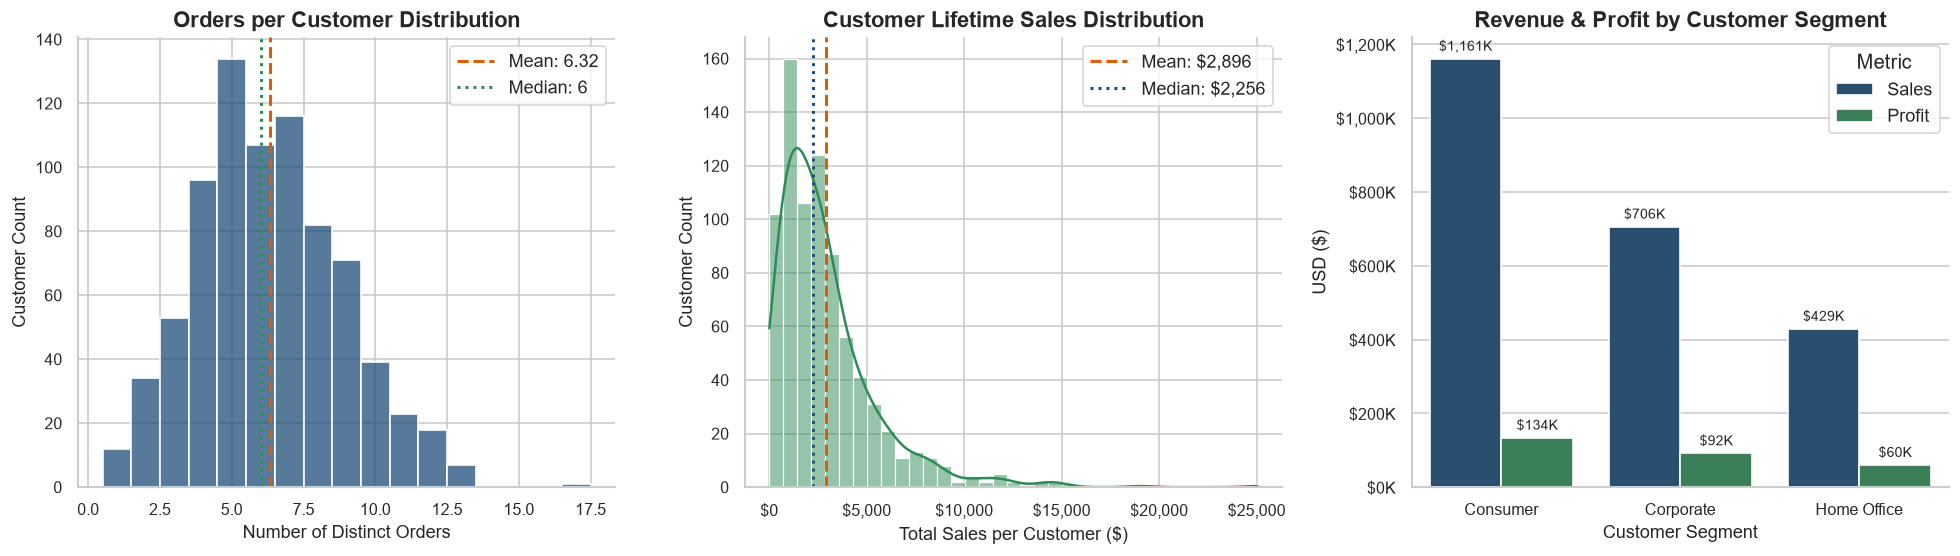

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

sns.histplot(customer_df["Orders"], bins=range(1, 19), discrete=True, color=PALETTE["primary"], edgecolor="white", ax=axes[0])
axes[0].axvline(customer_df["Orders"].mean(), color=PALETTE["accent"], linestyle="--", linewidth=1.8, label=f"Mean: {customer_df['Orders'].mean():.2f}")
axes[0].axvline(customer_df["Orders"].median(), color=PALETTE["secondary"], linestyle=":", linewidth=1.8, label=f"Median: {customer_df['Orders'].median():.0f}")
axes[0].set_title("Orders per Customer Distribution")
axes[0].set_xlabel("Number of Distinct Orders")
axes[0].set_ylabel("Customer Count")
axes[0].legend(frameon=True)

sns.histplot(customer_df["Total_Sales"], bins=35, kde=True, color=PALETTE["secondary"], edgecolor="white", ax=axes[1])
axes[1].axvline(customer_df["Total_Sales"].mean(), color=PALETTE["accent"], linestyle="--", linewidth=1.8, label=f"Mean: ${customer_df['Total_Sales'].mean():,.0f}")
axes[1].axvline(customer_df["Total_Sales"].median(), color=PALETTE["primary"], linestyle=":", linewidth=1.8, label=f"Median: ${customer_df['Total_Sales'].median():,.0f}")
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
axes[1].set_title("Customer Lifetime Sales Distribution")
axes[1].set_xlabel("Total Sales per Customer ($)")
axes[1].set_ylabel("Customer Count")
axes[1].legend(frameon=True)

seg_melt = seg_summary.melt(id_vars="Segment", value_vars=["Sales", "Profit"], var_name="Metric", value_name="Amount")
sns.barplot(data=seg_melt, x="Segment", y="Amount", hue="Metric", palette=[PALETTE["primary"], PALETTE["secondary"]], ax=axes[2])
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K"))
axes[2].set_title("Revenue & Profit by Customer Segment")
axes[2].set_xlabel("Customer Segment")
axes[2].set_ylabel("USD ($)")
for container in axes[2].containers:
    axes[2].bar_label(container, labels=[f"${v/1e3:,.0f}K" for v in container.datavalues], padding=3, fontsize=8.5)

plt.tight_layout()
plt.show()

In [6]:
print("Top 10 Customers by Lifetime Sales:")
display(customer_df.sort_values("Total_Sales", ascending=False).head(10)[
    ["Customer Name", "Segment", "Orders", "Total_Quantity", "Total_Sales", "Total_Profit", "Profit_Margin_Pct"]
].round(2))

Top 10 Customers by Lifetime Sales:


,Customer Name,Segment,Orders,Total_Quantity,Total_Sales,Total_Profit,Profit_Margin_Pct
700,Sean Miller,Home Office,5,50,25043.05,-1980.74,-7.91
741,Tamara Chand,Corporate,5,42,19052.22,8981.32,47.14
621,Raymond Buch,Consumer,6,71,15117.34,6976.10,46.15
730,Tom Ashbrook,Home Office,4,36,14595.62,4703.79,32.23
6,Adrian Barton,Consumer,10,73,14473.57,5444.81,37.62
434,Ken Lonsdale,Consumer,12,113,14175.23,806.86,5.69
669,Sanjit Chand,Consumer,9,87,14142.33,5757.41,40.71
327,Hunter Lopez,Consumer,6,50,12873.30,5622.43,43.68
683,Sanjit Engle,Consumer,11,78,12209.44,2650.68,21.71
131,Christopher Conant,Consumer,5,34,12129.07,2177.05,17.95


# Monthly Seasonality & Sales Velocity (2015–2018)

In [7]:
yearly_df = (
    df.groupby("Year", as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
)
yearly_df["Margin_Pct"] = yearly_df["Profit"] / yearly_df["Sales"] * 100
yearly_df["Sales_YoY_Pct"] = yearly_df["Sales"].pct_change() * 100

# Tampilkan lintasan pertumbuhan tahunan saja
print("--- Trajektori Penjualan & Profit Tahunan (YoY) ---")
display(yearly_df.round(2))

--- Trajektori Penjualan & Profit Tahunan (YoY) ---


,Year,Sales,Profit,Orders,Margin_Pct,Sales_YoY_Pct
0,2015,483966.13,49556.03,969,10.24,NaN
1,2016,470532.51,61618.60,1038,13.10,-2.78
2,2017,609205.60,81795.17,1315,13.43,29.47
3,2018,733215.26,93439.27,1687,12.74,20.36


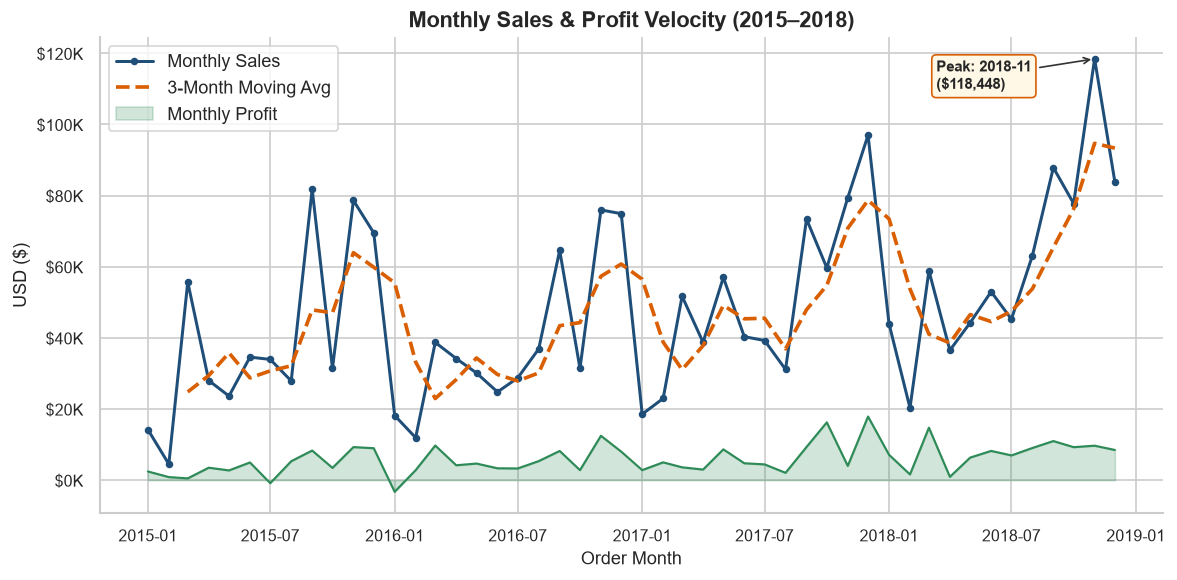

In [8]:
monthly_df = (
    df.groupby("Year_Month", as_index=False)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Year_Month")
)
monthly_df["Order_Month_Dt"] = pd.to_datetime(monthly_df["Year_Month"] + "-01")
monthly_df["Sales_3M_MA"] = monthly_df["Sales"].rolling(3).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_df["Order_Month_Dt"], monthly_df["Sales"], color=PALETTE["primary"], linewidth=1.8, marker="o", markersize=3.5, label="Monthly Sales")
ax.plot(monthly_df["Order_Month_Dt"], monthly_df["Sales_3M_MA"], color=PALETTE["accent"], linewidth=2.2, linestyle="--", label="3-Month Moving Avg")
ax.fill_between(monthly_df["Order_Month_Dt"], monthly_df["Profit"], color=PALETTE["secondary"], alpha=0.22, label="Monthly Profit")
ax.plot(monthly_df["Order_Month_Dt"], monthly_df["Profit"], color=PALETTE["secondary"], linewidth=1.3)

peak_row = monthly_df.loc[monthly_df["Sales"].idxmax()]
ax.annotate(
    f"Peak: {peak_row['Year_Month']}\n(${peak_row['Sales']:,.0f})",
    xy=(peak_row["Order_Month_Dt"], peak_row["Sales"]),
    xytext=(-95, -18), textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="#333333"),
    fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#fff8e7", ec=PALETTE["accent"])
)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K"))
ax.set_title("Monthly Sales & Profit Velocity (2015–2018)")
ax.set_xlabel("Order Month")
ax.set_ylabel("USD ($)")
ax.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

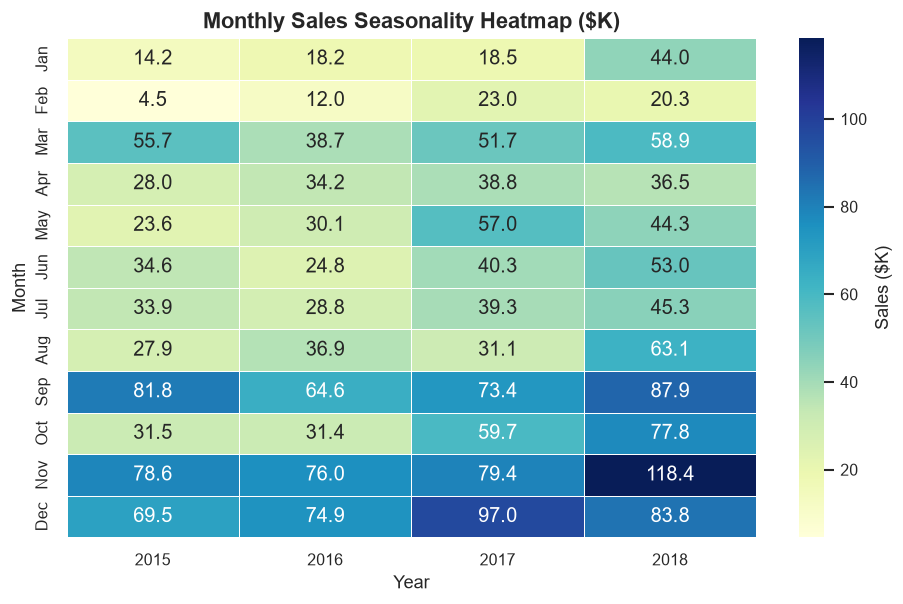

In [9]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season_pivot = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
season_pivot.index = month_order

fig, ax = plt.subplots(figsize=(8, 5.2))
sns.heatmap(
    season_pivot / 1e3, annot=True, fmt=".1f", cmap="YlGnBu",
    cbar_kws={"label": "Sales ($K)"}, linewidths=0.5, ax=ax
)
ax.set_title("Monthly Sales Seasonality Heatmap ($K)")
ax.set_xlabel("Year")
ax.set_ylabel("Month")
plt.tight_layout()
plt.show()

# Category, Sub-Category, Region & Segment Revenue

In [10]:
cat_summary = (
    df.groupby("Category", as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Quantity=("Quantity", "sum"),
           Orders=("Order ID", "nunique"), Avg_Discount=("Discount", "mean"))
      .sort_values("Sales", ascending=False)
)
cat_summary["Sales_Share_Pct"] = cat_summary["Sales"] / cat_summary["Sales"].sum() * 100
cat_summary["Profit_Share_Pct"] = cat_summary["Profit"] / cat_summary["Profit"].sum() * 100
cat_summary["Profit_Margin_Pct"] = cat_summary["Profit"] / cat_summary["Sales"] * 100

print("--- Kinerja Penjualan per Kategori Produk ---")
display(cat_summary.round(2))

--- Kinerja Penjualan per Kategori Produk ---


,Category,Sales,Profit,Quantity,Orders,Avg_Discount,Sales_Share_Pct,Profit_Share_Pct,Profit_Margin_Pct
2,Technology,836154.03,145454.95,6939,1544,0.13,36.40,50.79,17.40
0,Furniture,741718.42,18463.33,8026,1764,0.17,32.29,6.45,2.49
1,Office Supplies,719047.03,122490.80,22906,3742,0.16,31.30,42.77,17.04


In [11]:
reg_summary = (
    df.groupby(["Region", "Regional_Manager"], as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"),
           Avg_Discount=("Discount", "mean"))
      .sort_values("Profit", ascending=False)
)
reg_summary["Profit_Margin_Pct"] = reg_summary["Profit"] / reg_summary["Sales"] * 100
print("--- Analisis Kinerja Region & Manajer Regional ---")
display(reg_summary.round(2))

--- Analisis Kinerja Region & Manajer Regional ---


,Region,Regional_Manager,Sales,Profit,Orders,Avg_Discount,Profit_Margin_Pct
3,West,Anna Andreadi,725457.82,108418.45,1611,0.11,14.94
1,East,Chuck Magee,678499.87,91534.84,1401,0.15,13.49
2,South,Cassandra Brandow,391721.90,46749.43,822,0.15,11.93
0,Central,Kelly Williams,501239.89,39706.36,1175,0.24,7.92


In [12]:
multi_group = (
    df.groupby(["Category", "Region", "Segment"], as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
)
multi_group["Margin_Pct"] = multi_group["Profit"] / multi_group["Sales"] * 100
print("--- Kategori x Region x Segmen dengan Margin Terendah ---")
display(multi_group.sort_values("Margin_Pct").head(8).round(2))

--- Kategori x Region x Segmen dengan Margin Terendah ---


,Category,Region,Segment,Sales,Profit,Avg_Discount,Margin_Pct
2,Furniture,Central,Home Office,25482.34,-1198.61,0.28,-4.70
0,Furniture,Central,Consumer,86229.22,-3994.43,0.31,-4.63
13,Office Supplies,Central,Corporate,41137.70,99.29,0.26,0.24
4,Furniture,East,Corporate,64209.05,342.13,0.15,0.53
3,Furniture,East,Consumer,114211.80,2038.11,0.16,1.78
32,Technology,South,Home Office,37184.99,764.58,0.11,2.06
5,Furniture,East,Home Office,29588.98,677.99,0.15,2.29
12,Office Supplies,Central,Consumer,93111.48,2583.14,0.27,2.77


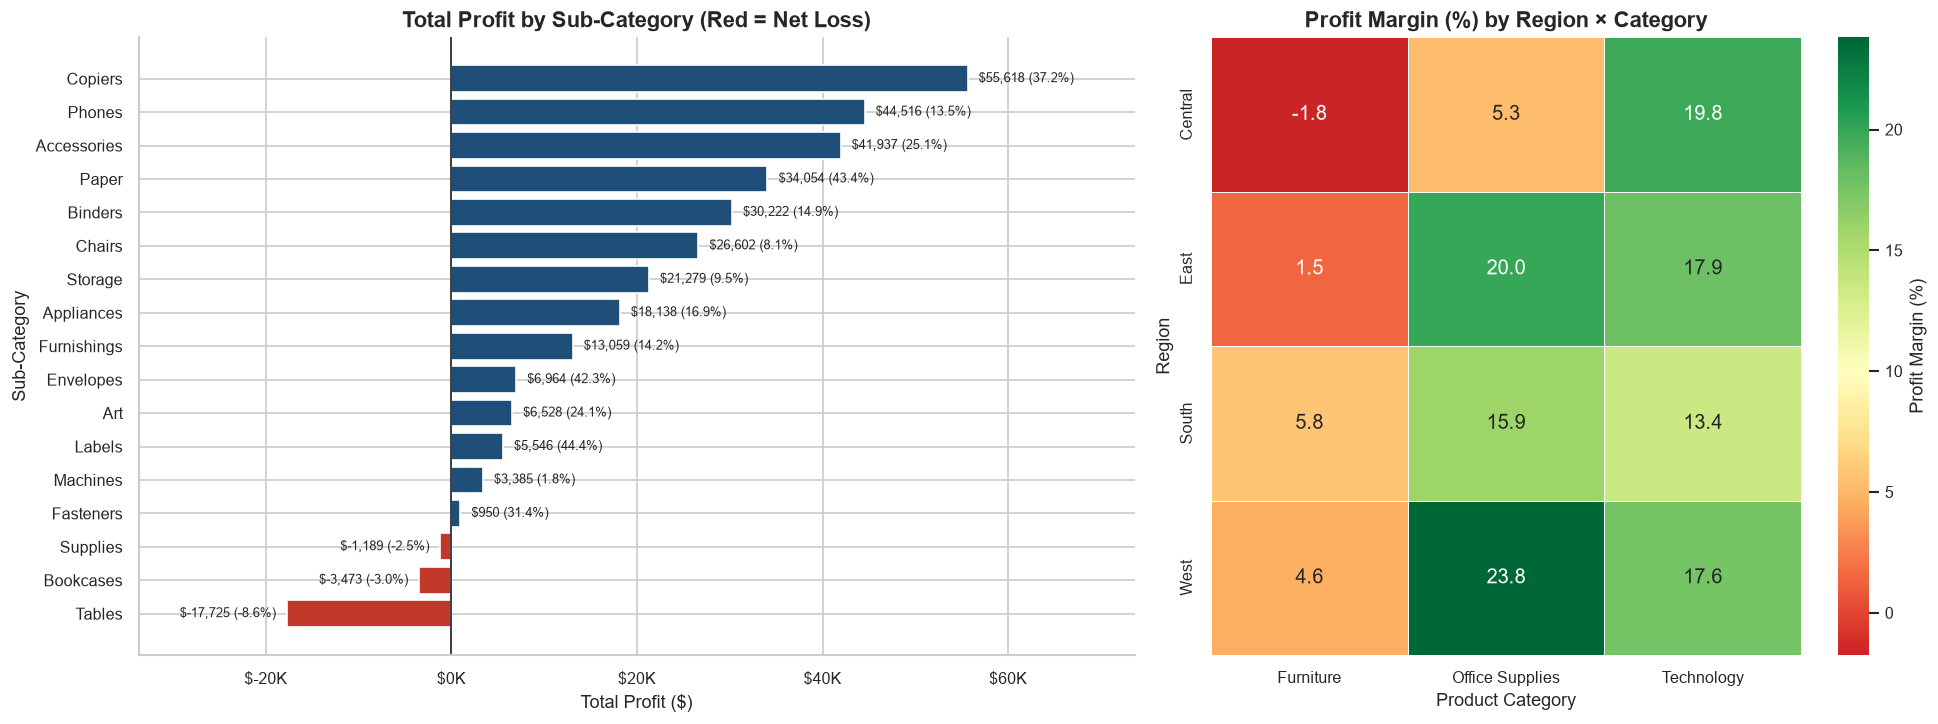

In [13]:
sub_df = (
    df.groupby(["Category", "Sub-Category"], as_index=False)
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
      .sort_values("Profit", ascending=True)
)
sub_df["Margin_Pct"] = sub_df["Profit"] / sub_df["Sales"] * 100

fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.2), gridspec_kw={"width_ratios": [1.35, 1.0]})

colors = [PALETTE["danger"] if p < 0 else PALETTE["primary"] for p in sub_df["Profit"]]
axes[0].barh(sub_df["Sub-Category"], sub_df["Profit"], color=colors, edgecolor="white")
axes[0].axvline(0, color="#222222", linewidth=1)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K"))
axes[0].set_title("Total Profit by Sub-Category (Red = Net Loss)")
axes[0].set_xlabel("Total Profit ($)")
axes[0].set_ylabel("Sub-Category")
for idx, (_, r) in enumerate(sub_df.iterrows()):
    offset = 1200 if r["Profit"] >= 0 else -1200
    ha = "left" if r["Profit"] >= 0 else "right"
    axes[0].text(r["Profit"] + offset, idx, f"${r['Profit']:,.0f} ({r['Margin_Pct']:.1f}%)", va="center", ha=ha, fontsize=8)
axes[0].set_xlim(sub_df["Profit"].min() - 16000, sub_df["Profit"].max() + 18000)

reg_cat_sales = df.pivot_table(index="Region", columns="Category", values="Sales", aggfunc="sum")
reg_cat_profit = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")
reg_cat_margin = (reg_cat_profit / reg_cat_sales) * 100

sns.heatmap(
    reg_cat_margin, annot=True, fmt=".1f", cmap="RdYlGn", center=10,
    cbar_kws={"label": "Profit Margin (%)"}, linewidths=0.6, ax=axes[1]
)
axes[1].set_title("Profit Margin (%) by Region × Category")
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Region")

plt.tight_layout()
plt.show()

# Discount Sensitivity & Profitability Threshold

In [14]:
disc_table = (
    df.groupby("Discount", as_index=False)
      .agg(
          Line_Items=("Row ID", "count"),
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Unprofitable_Lines=("Profit", lambda s: (s < 0).sum())
      )
      .sort_values("Discount")
)
disc_table["Margin_Pct"] = disc_table["Profit"] / disc_table["Sales"] * 100
disc_table["Loss_Rate_Pct"] = disc_table["Unprofitable_Lines"] / disc_table["Line_Items"] * 100
disc_table["Discount_Pct"] = (disc_table["Discount"] * 100).astype(int).astype(str) + "%"

print("--- Profil Profitabilitas Berdasarkan Tingkat Diskon ---")
display(disc_table[["Discount_Pct", "Line_Items", "Sales", "Profit", "Margin_Pct", "Loss_Rate_Pct"]].round(2))

--- Profil Profitabilitas Berdasarkan Tingkat Diskon ---


,Discount_Pct,Line_Items,Sales,Profit,Margin_Pct,Loss_Rate_Pct
0,0%,4798,1087908.47,320987.60,29.51,0.00
1,10%,94,54369.35,9029.18,16.61,4.26
2,15%,52,27558.52,1418.99,5.15,32.69
3,20%,3657,764594.37,90337.31,11.82,13.73
4,30%,226,102945.28,-10357.22,-10.06,91.59
5,32%,27,14493.46,-2391.14,-16.50,100.00
6,40%,206,116417.78,-23057.05,-19.81,87.38
7,45%,11,5484.97,-2493.11,-45.45,100.00
8,50%,66,58918.54,-20506.43,-34.80,100.00
9,60%,138,6644.70,-5944.66,-89.46,100.00


In [15]:
tier_table = (
    df.groupby("Discount_Tier", observed=False, as_index=False)
      .agg(Line_Items=("Row ID", "count"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
           Loss_Rate_Pct=("Profit", lambda s: (s < 0).mean() * 100))
)
tier_table["Margin_Pct"] = tier_table["Profit"] / tier_table["Sales"] * 100
print("--- Analisis Margin Profit & Loss Rate Berdasarkan Tier Diskon ---")
display(tier_table.round(2))

--- Analisis Margin Profit & Loss Rate Berdasarkan Tier Diskon ---


,Discount_Tier,Line_Items,Sales,Profit,Loss_Rate_Pct,Margin_Pct
0,No Discount (0%),4798,1087908.47,320987.60,0.00,29.51
1,Low (1%–20%),3803,846522.24,100785.47,13.75,11.91
2,Medium (21%–40%),459,233856.53,-35805.41,90.20,-15.31
3,High (>40%),933,128632.25,-99558.59,100.00,-77.40


Pearson r (Discount vs. Profit)       : -0.219
Pearson r (Discount vs. Profit Margin): -0.864


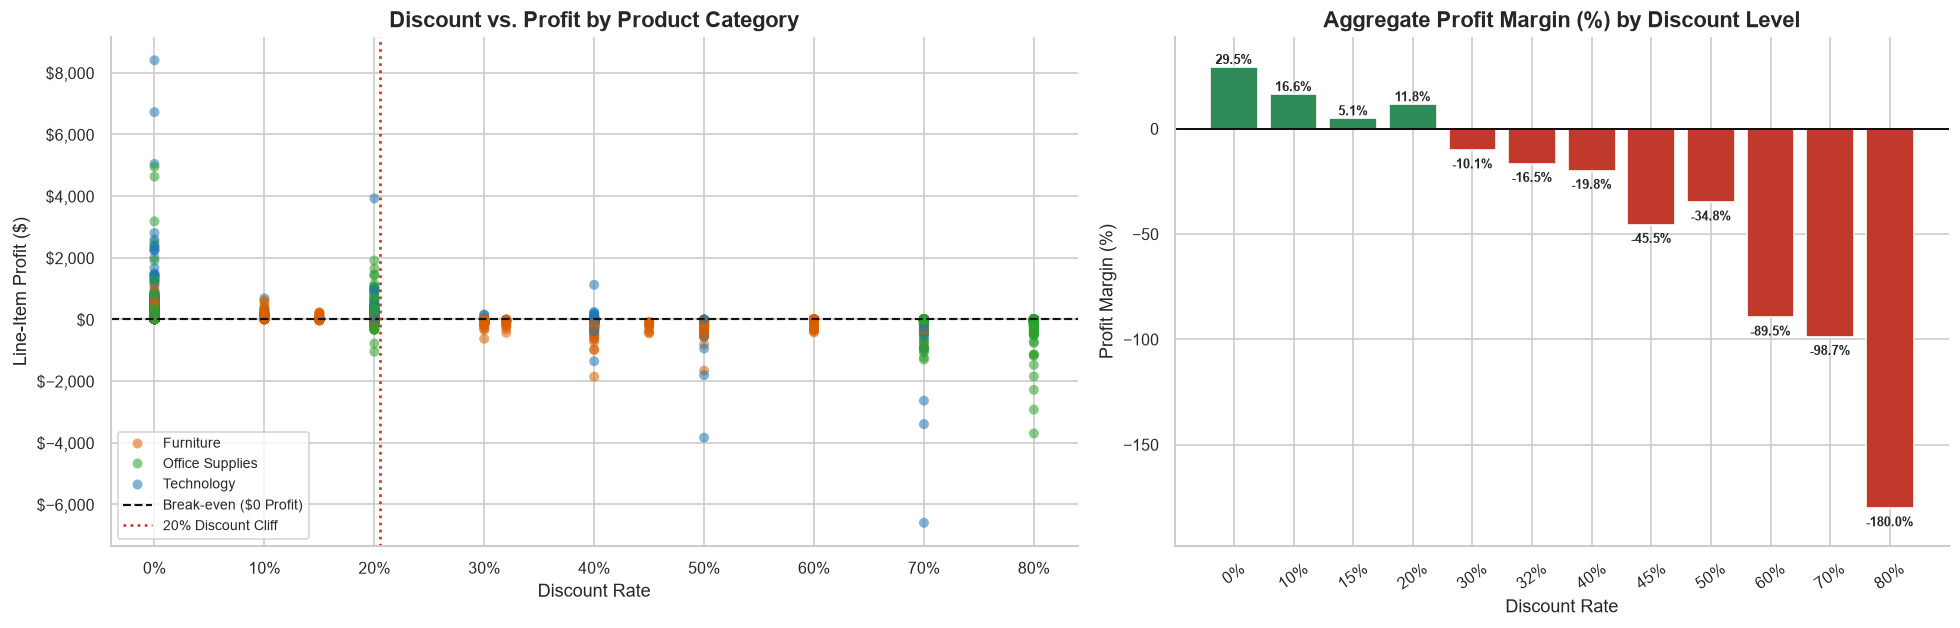

In [16]:
print(f"Pearson r (Discount vs. Profit)       : {df['Discount'].corr(df['Profit']):.3f}")
print(f"Pearson r (Discount vs. Profit Margin): {df['Discount'].corr(df['Profit_Margin']):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.4), gridspec_kw={"width_ratios": [1.25, 1.0]})

cat_colors = {
    "Technology": PALETTE["Tech"],
    "Office Supplies": PALETTE["Office"],
    "Furniture": PALETTE["Furniture"],
}
sns.scatterplot(
    data=df, x="Discount", y="Profit", hue="Category",
    palette=cat_colors, alpha=0.55, s=36, edgecolor="none", ax=axes[0]
)
axes[0].axhline(0, color="#111111", linewidth=1.3, linestyle="--", label="Break-even ($0 Profit)")
axes[0].axvline(0.205, color=PALETTE["danger"], linewidth=1.6, linestyle=":", label="20% Discount Cliff")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
axes[0].set_title("Discount vs. Profit by Product Category")
axes[0].set_xlabel("Discount Rate")
axes[0].set_ylabel("Line-Item Profit ($)")
axes[0].legend(loc="lower left", frameon=True, fontsize=8.5)

bar_colors = [PALETTE["secondary"] if m >= 0 else PALETTE["danger" ] for m in disc_table["Margin_Pct"]]
axes[1].bar(disc_table["Discount_Pct"], disc_table["Margin_Pct"], color=bar_colors, edgecolor="white")
axes[1].axhline(0, color="#111111", linewidth=1.2)
axes[1].set_title("Aggregate Profit Margin (%) by Discount Level")
axes[1].set_xlabel("Discount Rate")
axes[1].set_ylabel("Profit Margin (%)")
axes[1].tick_params(axis="x", rotation=35)
for idx, (_, r) in enumerate(disc_table.iterrows()):
    y_pos = r["Margin_Pct"] + (3 if r["Margin_Pct"] >= 0 else -7)
    axes[1].text(idx, y_pos, f"{r['Margin_Pct']:.1f}%", ha="center", va="center", fontsize=8, fontweight="bold")
axes[1].set_ylim(disc_table["Margin_Pct"].min() - 18, disc_table["Margin_Pct"].max() + 14)

plt.tight_layout()
plt.show()

## Executive Summary: 5 Annotated Business Findings

1. **The 20% Discount Cliff (`Discount > 20%` Destroys \$135K in Profit):**
   Orders with 0%–20% discount (86.1% of line items) generated \$1,934,430.71 in sales and \$421,773.08 in profit (21.80% margin). Once discounts exceed 20% (30%–80%, 13.9% of line items), every tier becomes net unprofitable—generating \$362,488.78 in sales while losing -\$135,364.00 (-37.34% margin, with 96.8% of line items losing money; $r = -0.864$ between Discount and Profit Margin). *Recommendation: Cap standard sales rep discounts at 20% and require director approval for deeper markdowns.*

2. **Technology & Office Supplies Drive 93.6% of Profit While Furniture Bleeds Margin:**
   While revenue is evenly split across categories (~31%–36% each), **Technology** (\$145,454.95 profit, 17.40% margin) and **Office Supplies** (\$122,490.80 profit, 17.04% margin) generate 93.55% of total profit. **Furniture** contributes only \$18,463.33 (2.49% margin) due to heavy losses in **Tables** (-\$17,725.48, -8.56% margin) and **Bookcases** (-\$3,472.56, -3.02% margin). *Recommendation: Restrict discounting and review pricing/freight costs on Tables and Bookcases; focus growth on high-margin Copiers (37.2% margin) and Accessories.*

3. **Strong Q4 Seasonality (51.6% of Revenue in Sep–Dec) & Accelerating YoY Growth:**
   Annual revenue grew +51.5% from 2015 (\$483,966) to 2018 (\$733,215). Demand is heavily concentrated in **Sep–Dec (51.62% of total sales)**, with **Q4 (Oct–Dec) alone driving 38.23%**. Peak months **November (\$352,461)** and **December (\$325,294)** outperform **February (\$59,751)** by nearly 6×. *Recommendation: Pre-position inventory before September and run targeted Q1 reactivation promotions to lift February–March volume.*

4. **Central Region Suffers Margin Leakage (7.92% vs. West's 14.94%) Due to Over-Discounting:**
   **West** leads in both total profit (\$108,418) and margin (14.94%) with disciplined discounting (10.9% avg). Conversely, **Central** generates 28% more sales than South (\$501,240 vs. \$391,722) yet produces the lowest profit (\$39,706, 7.92% margin), driven by an average discount of 24.0% (and -1.8% margin in Central Furniture). *Recommendation: Audit Central region discounting governance, especially for Furniture and Binders.*

5. **High Customer Retention (98.5% Repeat Rate) With Untapped B2B Margin Upside:**
   Across 793 unique customers, 98.49% (781) placed 2+ orders (averaging 6.32 orders and \$2,896.49 lifetime spend). **Consumer** accounts for 50.56% of revenue at an 11.55% margin (\$449.11 AOV), whereas **Home Office** (14.05% margin, \$472.36 AOV) and **Corporate** (13.03% margin, \$466.41 AOV) deliver stronger per-order economics. *Recommendation: Prioritize B2B retention and account expansion in Corporate and Home Office segments.*